# Schedule Delay Analysis with a Small Decision Tree

Flag tasks at risk of finishing more than three days late using a small, readable decision tree.

**Beginner/intermediate learning project. Synthetic data only. AI-assisted implementation.**
Учебный проект начального/среднего уровня, созданный с помощью AI. Данные синтетические.

Run this notebook from its project folder. Read the short Python cells in order; the CSV and generator are included.


## 1. Read the task records
One independent fictional task per project. / Одна независимая учебная задача на проект. The CSV includes planned and actual duration for historical training.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/synthetic_data.csv")
print(df.head())
df.info()
print(df.describe().round(2))
print("Missing values:")
print(df.isna().sum())

   task_id  planned_days  ...  rain_forecast_days  crew_size
0        1            29  ...                   1          8
1        2            58  ...                   7         21
2        3            47  ...                   5         11
3        4            31  ...                   2         19
4        5            21  ...                   4         10

[5 rows x 6 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   task_id             160 non-null    int64
 1   planned_days        160 non-null    int64
 2   actual_days         160 non-null    int64
 3   material_ready      160 non-null    int64
 4   rain_forecast_days  160 non-null    int64
 5   crew_size           160 non-null    int64
dtypes: int64(6)
memory usage: 7.6 KB
       task_id  planned_days  ...  rain_forecast_days  crew_size
count   160.00        160.00 

## 2. Find delays and count them with Pandas
Calculate delay just as in our Python lessons. A positive label means more than three days late. / Считаем задержку, как на наших занятиях. Единица означает задержку больше трёх дней.


                count   mean
material_ready              
0                  85  0.765
1                  75  0.187
Delayed by more than 3 days: 79


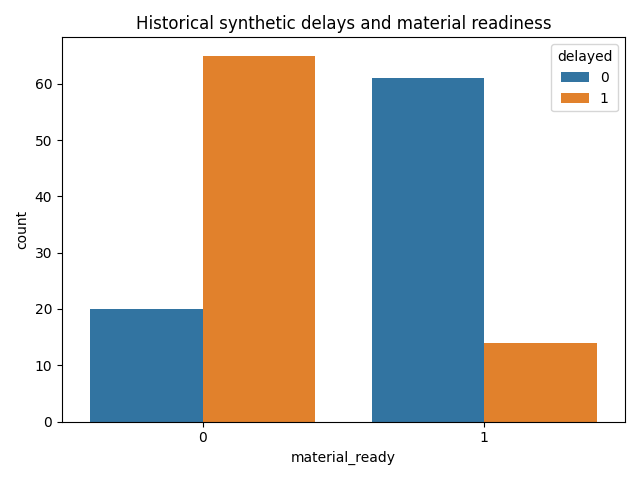

In [2]:
df["delay_days"] = df["actual_days"] - df["planned_days"]
df["delayed"] = (df["delay_days"] > 3).astype(int)
summary = df.groupby("material_ready")["delayed"].agg(["count", "mean"])
print(summary.round(3).to_string())
print("Delayed by more than 3 days:", df["delayed"].sum())
sns.countplot(data=df, x="material_ready", hue="delayed")
plt.title("Historical synthetic delays and material readiness")
plt.tight_layout()
plt.savefig("results/pandas_exploration.png")
plt.close()

## 3. Split independent tasks into training and testing
Inputs describe kickoff readiness, a weather forecast and assigned workers. / Признаки — готовность материалов, прогноз дождя и численность бригады. Actual duration and delay are never inputs.


In [3]:
# These inputs are known or forecast at kickoff, before the actual finish.
from sklearn.model_selection import train_test_split
X = df[["material_ready", "rain_forecast_days", "crew_size"]]
y = df["delayed"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

## 4. Train a tree with only two levels
A depth-two tree makes a small number of readable decisions. / Дерево глубиной два даёт несколько понятных правил. Depth is fixed before testing.


In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, y_train)
predicted = model.predict(X_test)

## 5. Check alerts and compare with a simple baseline
Accuracy alone is insufficient: precision checks alerts, recall checks missed delays. / Precision — доля верных предупреждений; recall — доля найденных задержек.


In [5]:
# The baseline always predicts the most common training outcome.
from sklearn.metrics import accuracy_score, precision_score, recall_score
baseline = [y_train.mode()[0]] * len(y_test)
print(f"Tree accuracy: {accuracy_score(y_test, predicted):.3f}")
print(f"Baseline accuracy: {accuracy_score(y_test, baseline):.3f}")
print(f"Alert precision: {precision_score(y_test, predicted, zero_division=0):.3f}")
print(f"Delay recall: {recall_score(y_test, predicted, zero_division=0):.3f}")

Tree accuracy: 0.750
Baseline accuracy: 0.500
Alert precision: 0.857
Delay recall: 0.600


## 6. Draw the actual decision rules
The picture displays the fitted rules. / График показывает правила самого дерева. A new-task prediction is an alert for a planner, not a guaranteed outcome.


New task delay alert: 1


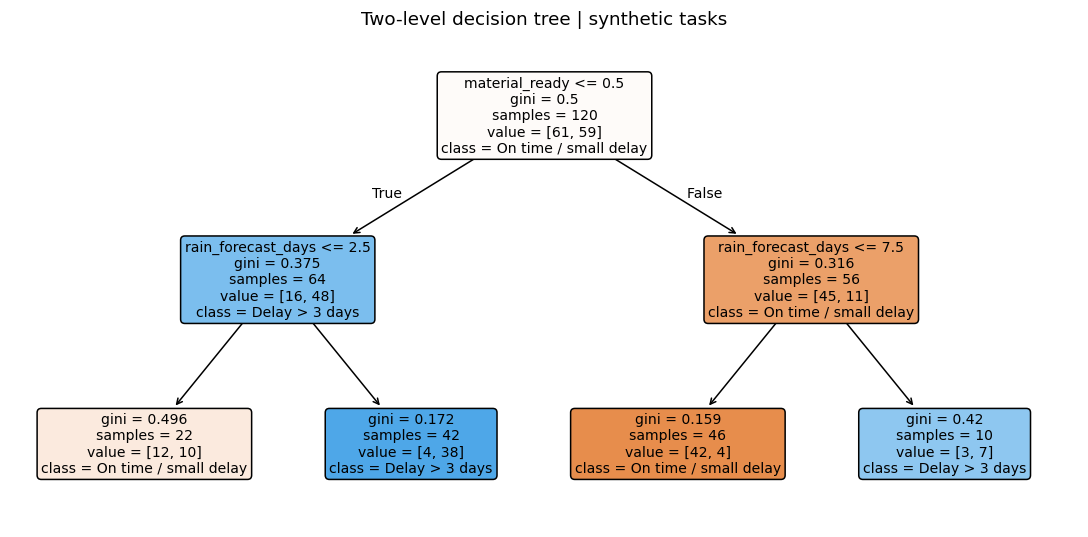

In [6]:
plt.figure(figsize=(10, 5))
plot_tree(model, feature_names=list(X.columns), class_names=["On time / small delay", "Delay > 3 days"], filled=True, rounded=True)
plt.title("Two-level decision tree | synthetic tasks")
plt.tight_layout()
plt.savefig("results/evaluation.png")
new_task = pd.DataFrame({"material_ready": [0], "rain_forecast_days": [5], "crew_size": [12]})
print("New task delay alert:", int(model.predict(new_task)[0]))

Educational project using synthetic data. Results require validation on real operational data.
